In [1]:
#1. import packages
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
#stage 1. load and preprocess data
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [4]:
#display 2 sample images
plt.figure(figsize=(5, 3))

<Figure size 500x300 with 0 Axes>

<Figure size 500x300 with 0 Axes>

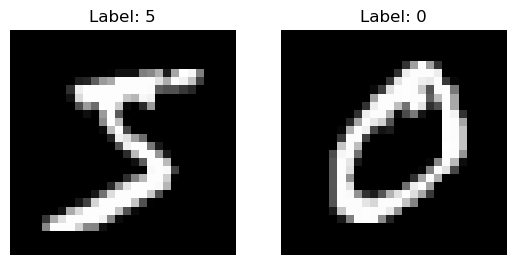

In [5]:
for i in range(2):
    plt.subplot(1, 2, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Label: " +str(y_train[i]))
    plt.axis('off')

plt.show()

In [6]:
# stage 2 define CNN architecture 
model = tf.keras.Sequential([
    tf.keras.layers.Reshape((28, 28, 1), input_shape=(28, 28)),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

C:\Users\KHUSHI\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
# compile model 
model.compile(optimizer='adam', 
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])

In [10]:
#stage 3: train the model 
model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.9498 - loss: 0.1730
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.9815 - loss: 0.0622
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9870 - loss: 0.0425
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9908 - loss: 0.0306
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.9923 - loss: 0.0236


In [11]:
#stage 4: evaluate model performance
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9857 - loss: 0.0449
Test Loss: 0.044870465993881226
Test Accuracy: 0.9857000112533569
